In [11]:
import librosa
from IPython.display import HTML  # this is for displaying metadata about the example
import matplotlib.pyplot as plt
import numpy as np
#from documentation

In [12]:
path = "/Users/medurarvind/pdhc/data/hc/AVPEPUDEAC0001_a.wav"
filename = "AVPEPUDEAC0001_a.wav"
audio, sr = librosa.load(path, sr=16000)
print(audio,sr)
print("number of samples: ", audio.shape)
print("duration (s): ", audio.shape[0] / sr)

# And print out some information about this example
#setting of sampling rate: sr=None or sr = 160000

[-2.6713201e-04 -4.4681650e-04 -4.4248410e-04 ...  3.3259828e-04
  7.0051174e-05  7.5731346e-05] 16000
number of samples:  (35271,)
duration (s):  2.2044375


[Text(0.5, 1.0, 'Plot of the audio file : AVPEPUDEAC0001_a.wav')]

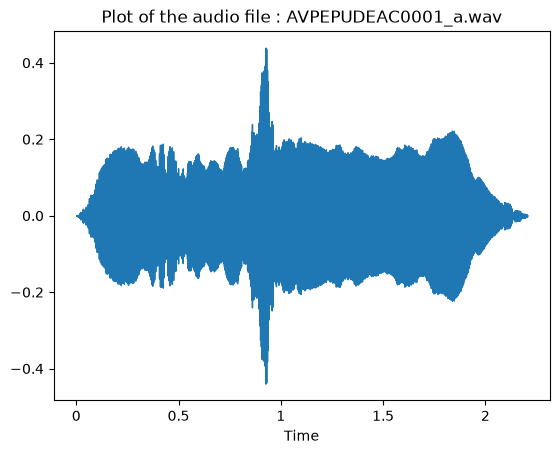

In [13]:
fig,ax=plt.subplots()
librosa.display.waveshow(audio,sr=sr,ax=ax)
ax.set(title=f"Plot of the audio file : {filename}")

In [14]:
audio_dft=np.fft.fft(audio)
frequencies = np.fft.fftfreq(len(audio), d=1 / sr)

[Text(0.5, 1.0, 'Frequency domain representation'),
 Text(0.5, 0, 'Frequency (Hz)'),
 Text(0, 0.5, 'Magnitude')]

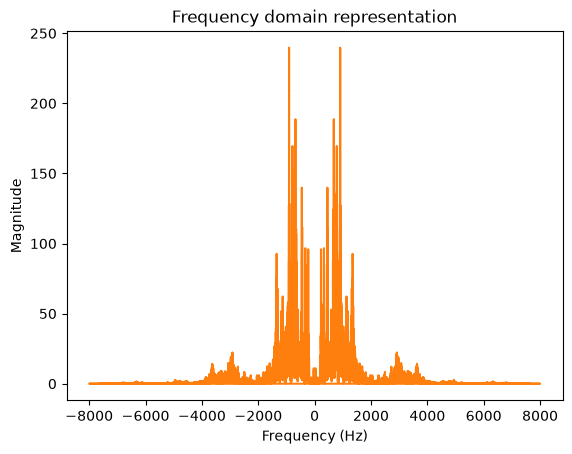

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.plot(frequencies, np.abs(audio_dft), color="C1")
ax.set(title="Frequency domain representation",
          xlabel="Frequency (Hz)",
          ylabel="Magnitude")

[Text(0.5, 1.0, 'Frequency domain representation'),
 Text(0.5, 0, 'Frequency (Hz)'),
 Text(0, 0.5, 'Magnitude')]

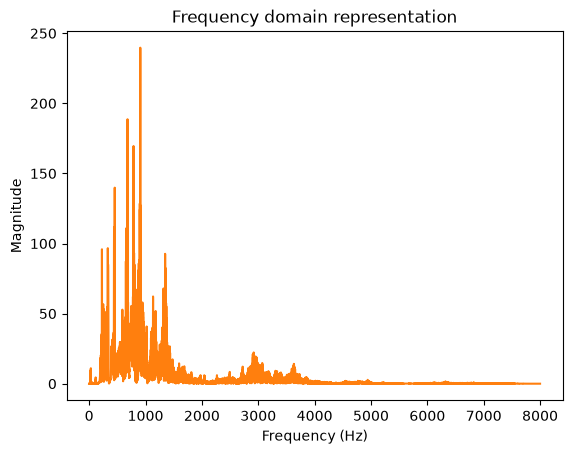

In [16]:
#instead use the rfft:
audio_dft=np.fft.rfft(audio)
frequencies = np.fft.rfftfreq(len(audio), d=1 / sr)
fig, ax = plt.subplots()
ax.plot(frequencies, np.abs(audio_dft), color="C1")
ax.set(title="Frequency domain representation",
          xlabel="Frequency (Hz)",
          ylabel="Magnitude")

In [17]:
stft = librosa.stft(audio)

[Text(0.5, 1.0, 'Time-domain')]

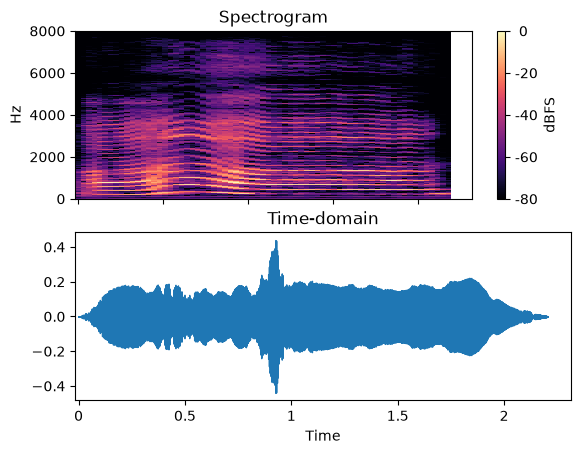

In [18]:
fig, ax = plt.subplots(nrows=2, sharex=True)
img = librosa.display.specshow(stft, vscale="dBFS",
                               sr=sr, hop_length=512, x_axis="time", y_axis="hz", ax=ax[0])
librosa.display.colorbar_db(img, label="dBFS")
ax[0].set(title="Spectrogram")
ax[0].label_outer()
librosa.display.waveshow(audio, sr=sr, ax=ax[1])
ax[1].set(title="Time-domain")

In [19]:
import os

hc_dir = "/Users/medurarvind/pdhc/data/hc"
pd_dir = "/Users/medurarvind/pdhc/data/pd"

hc_files = [f for f in os.listdir(hc_dir) if f.endswith(".wav")]
pd_files = [f for f in os.listdir(pd_dir) if f.endswith(".wav")]

print(f"HC files: {len(hc_files)}")
print(f"PD files: {len(pd_files)}")
print(f"Total: {len(hc_files) + len(pd_files)}")

HC files: 2600
PD files: 2599
Total: 5199


In [22]:

# Trim the beginning and ending silence
audio_trimmed, index = librosa.effects.trim(audio)
# Print the durations
print(audio_trimmed.shape[0] / sr,audio.shape[0] / sr)

2.2044375 2.2044375
